<a href="https://colab.research.google.com/github/vikramsimha2510/VLM/blob/main/NITPY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
!git clone https://github.com/vikramsimha2510/VLM.git

fatal: destination path 'VLM' already exists and is not an empty directory.


In [25]:
%cd /content/VLM

/content/VLM


Satellite images: 70
Normal urban images: 30
Total images: 100


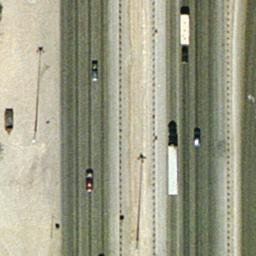

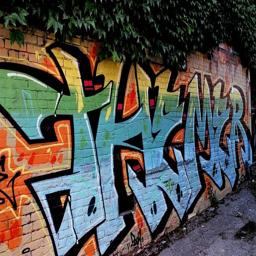

In [26]:

from pathlib import Path
from PIL import Image
from IPython.display import display

# Actual GitHub dataset locations
satellite_path = Path("/content/VLM/DATASETS/Satellite")
normal_path = Path("/content/VLM/DATASETS/Normal_Urban")

# Find images
satellite_images = list(satellite_path.rglob("*.jpg"))
normal_images = list(normal_path.rglob("*.jpg"))

print("Satellite images:", len(satellite_images))
print("Normal urban images:", len(normal_images))
print("Total images:", len(satellite_images) + len(normal_images))

# Display one satellite image
if satellite_images:
    display(Image.open(satellite_images[0]))

# Display one normal urban image
if normal_images:
    display(Image.open(normal_images[0]))


In [27]:
from collections import Counter

satellite_counts = Counter(
    image.stem.rsplit("_", 1)[0]
    for image in satellite_images
)

normal_counts = Counter(
    image.stem.rsplit("_", 1)[0]
    for image in normal_images
)

print("SATELLITE CATEGORY DISTRIBUTION")
for category, count in sorted(satellite_counts.items()):
    print(category, ":", count)

print("\nNORMAL URBAN CATEGORY DISTRIBUTION")
for category, count in sorted(normal_counts.items()):
    print(category, ":", count)

SATELLITE CATEGORY DISTRIBUTION
buildings : 10
denseresidential : 10
forest : 10
freeway : 10
golfcourse : 10
intersection : 10
mediumresidential : 10

NORMAL URBAN CATEGORY DISTRIBUTION
building : 5
cafe : 5
cars : 5
house : 5
road : 5
supermarket : 5


In [28]:

from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

# Correct category extraction from filenames
satellite_counts = Counter(
    img.stem.rsplit("_", 1)[0]
    for img in satellite_images
)

normal_counts = Counter(
    img.stem.rsplit("_", 1)[0]
    for img in normal_images
)

print("SATELLITE CATEGORY DISTRIBUTION")
for category, count in sorted(satellite_counts.items()):
    print(f"{category}: {count}")

print("\nNORMAL URBAN CATEGORY DISTRIBUTION")
for category, count in sorted(normal_counts.items()):
    print(f"{category}: {count}")

# Check image integrity and dimensions
all_images = satellite_images + normal_images
corrupted = []
dimensions = Counter()

for path in all_images:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            dimensions[img.size] += 1

    except Exception as e:
        corrupted.append((path.name, str(e)))

print("\nIMAGE QUALITY CHECK")
print("Total images:", len(all_images))
print("Corrupted images:", len(corrupted))
print("Image dimensions:", dimensions)

if corrupted:
    print("\nCorrupted files:")
    for name, error in corrupted:
        print(name, error)


SATELLITE CATEGORY DISTRIBUTION
buildings: 10
denseresidential: 10
forest: 10
freeway: 10
golfcourse: 10
intersection: 10
mediumresidential: 10

NORMAL URBAN CATEGORY DISTRIBUTION
building: 5
cafe: 5
cars: 5
house: 5
road: 5
supermarket: 5

IMAGE QUALITY CHECK
Total images: 100
Corrupted images: 0
Image dimensions: Counter({(256, 256): 99, (256, 251): 1})


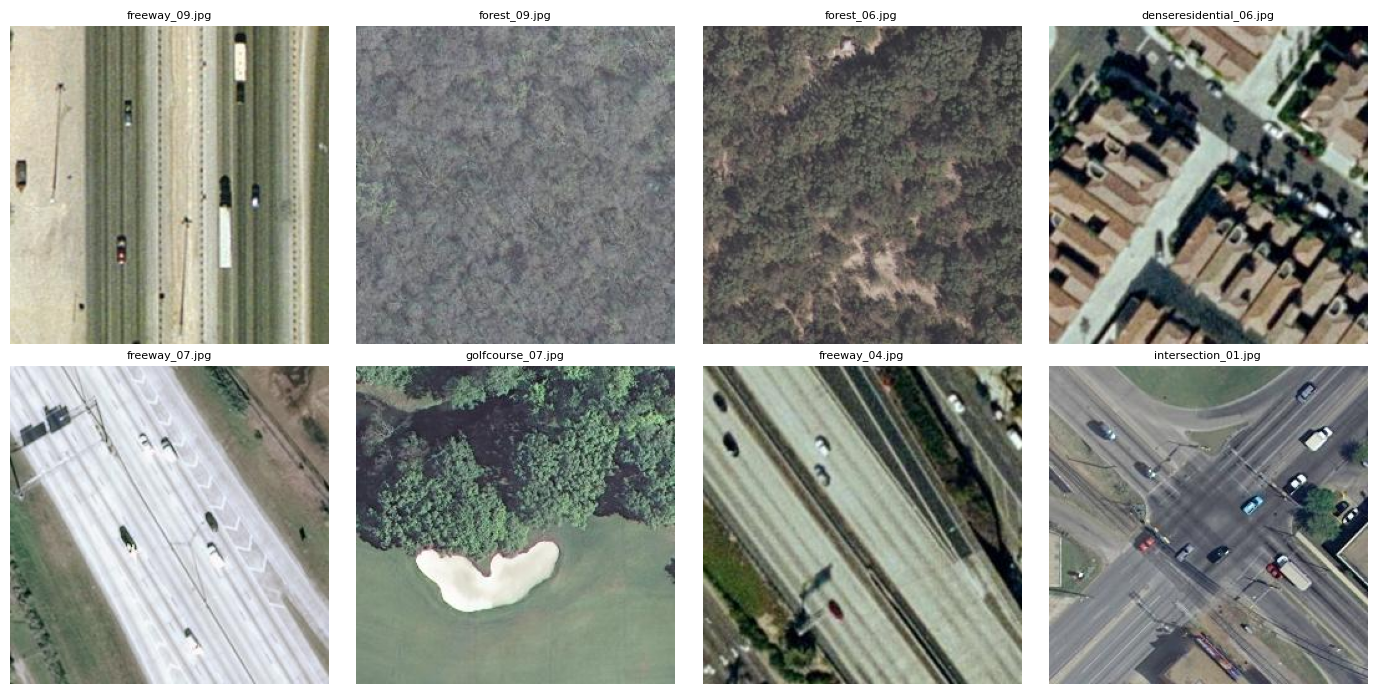

In [29]:

import matplotlib.pyplot as plt
from PIL import Image

sample_images = satellite_images[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, path in zip(axes.flat, sample_images):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


File: cafe_02.jpg | size: (256, 256) | true type: normal


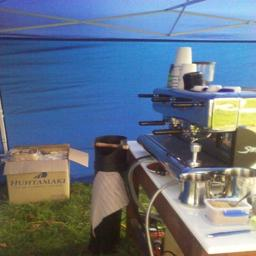

In [30]:
import random
from pathlib import Path
from PIL import Image
from IPython.display import display

DATA_ROOT = Path("/content/VLM/DATASETS")
EXTS = {".jpg", ".jpeg", ".png", ".webp"}

def load_input(path=None, seed=None):
    """path=None -> random image from the dataset.
       path='any/image.jpg' -> that image (works on any image)."""
    if path is None:
        files = [p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in EXTS]
        path = random.Random(seed).choice(files)
    path = Path(path)
    image = Image.open(path).convert("RGB")
    # ground truth is only known for dataset images
    true_type = None
    if str(DATA_ROOT) in str(path):
        true_type = "satellite" if "Satellite" in path.parts else "normal"
    return path, image, true_type

# ---- choose ONE ----
image_path, image, true_type = load_input()                      # random from dataset
# image_path, image, true_type = load_input("/content/my_image.jpg")   # your own image

# Optional: upload your own image in Colab
# from google.colab import files
# up = files.upload()
# image_path, image, true_type = load_input(list(up)[0])

print(f"File: {image_path.name} | size: {image.size} | true type: {true_type}")
display(image)

In [31]:
%pip install -q open_clip_torch

import torch, open_clip

device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")
clip_model = clip_model.to(device).eval()

NORMAL_PROMPTS = ["a photo taken from the ground level",
                  "a street-level photograph of a city",
                  "a close-up photo of a shop, car or building",
                  "a normal everyday photograph"]
SAT_PROMPTS    = ["a satellite image",
                  "an aerial view from above",
                  "a remote sensing image of a city",
                  "a top-down overhead view of buildings and roads"]

def _text_emb(prompts):
    with torch.no_grad():
        t = clip_model.encode_text(clip_tokenizer(prompts).to(device))
        t = t / t.norm(dim=-1, keepdim=True)
        t = t.mean(0)
        return t / t.norm()

TEXT = torch.stack([_text_emb(NORMAL_PROMPTS), _text_emb(SAT_PROMPTS)])   # [normal, satellite]

def classify_image(image, low_conf=0.75):
    """Zero-shot router: needs no training, so it works on any image."""
    x = clip_preprocess(image).unsqueeze(0).to(device)
    with torch.no_grad():
        f = clip_model.encode_image(x)
        f = f / f.norm(dim=-1, keepdim=True)
        probs = (100 * f @ TEXT.T).softmax(dim=-1)[0].cpu().tolist()
    p_normal, p_sat = probs
    label = "satellite" if p_sat > p_normal else "normal"
    conf = max(p_normal, p_sat)
    return {"label": label, "p_normal": round(p_normal, 3), "p_satellite": round(p_sat, 3),
            "confidence": round(conf, 3), "low_confidence": conf < low_conf}

result = classify_image(image)
print("Predicted type :", result["label"])
print("Probabilities  : normal =", result["p_normal"], "| satellite =", result["p_satellite"])
if result["low_confidence"]:
    print("Warning: low confidence, this image may be neither a clear photo nor a satellite view")
if true_type:
    print("True type      :", true_type, "->", "correct" if result["label"] == true_type else "WRONG")

Predicted type : satellite
Probabilities  : normal = 0.382 | satellite = 0.618
True type      : normal -> WRONG


In [32]:
import time, torch, pandas as pd
from transformers import BlipProcessor, BlipForConditionalGeneration

NORMAL_CAPTIONERS = {
    "BLIP-base":  "Salesforce/blip-image-captioning-base",
    "BLIP-large": "Salesforce/blip-image-captioning-large",
}
_cap_cache = {}
dtype = torch.float16 if device == "cuda" else torch.float32

def clip_match(image, text):
    """CLIP image-text cosine similarity (higher = caption matches image better)."""
    x = clip_preprocess(image).unsqueeze(0).to(device)
    t = clip_tokenizer([text]).to(device)
    with torch.no_grad():
        fi = clip_model.encode_image(x); fi = fi / fi.norm(dim=-1, keepdim=True)
        ft = clip_model.encode_text(t);  ft = ft / ft.norm(dim=-1, keepdim=True)
    return round((fi @ ft.T).item(), 4)

def caption_normal(image):
    rows = []
    for name, repo in NORMAL_CAPTIONERS.items():
        if name not in _cap_cache:
            proc = BlipProcessor.from_pretrained(repo)
            model = BlipForConditionalGeneration.from_pretrained(repo, torch_dtype=dtype).to(device).eval()
            _cap_cache[name] = (proc, model)
        proc, model = _cap_cache[name]
        inputs = proc(images=image, return_tensors="pt").to(device, dtype)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=40, num_beams=3)
        if device == "cuda": torch.cuda.synchronize()
        caption = proc.decode(out[0], skip_special_tokens=True).strip()
        rows.append({"model": name, "caption": caption,
                     "clip_match": clip_match(image, caption),
                     "seconds": round(time.time() - t0, 2)})
    return pd.DataFrame(rows)

FORCE = False   # True = run normal captioners even on a satellite image (for the general-vs-specialist comparison)

if result["label"] == "normal" or FORCE:
    pd.set_option("display.max_colwidth", None)
    normal_caps = caption_normal(image)
    display(normal_caps)
else:
    print("Predicted satellite -> use the satellite branch (next cells)")

Predicted satellite -> use the satellite branch (next cells)


In [33]:
import time, torch, pandas as pd
from transformers import BlipProcessor, BlipForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
_sat_cache = globals().get("_sat_cache", {})

SAT_CAPTIONERS = {   # name: (model repo, processor repo)
    "RSICD-BLIP (specialist)": ("Gurveer05/blip-image-captioning-base-rscid-finetuned",
                                "Salesforce/blip-image-captioning-base"),
    "BLIP-base (general)":     ("Salesforce/blip-image-captioning-base",
                                "Salesforce/blip-image-captioning-base"),
    "BLIP-large (general)":    ("Salesforce/blip-image-captioning-large",
                                "Salesforce/blip-image-captioning-large"),
}

def caption_satellite(image):
    rows = []
    for name, (model_repo, proc_repo) in SAT_CAPTIONERS.items():
        if name not in _sat_cache:
            proc = BlipProcessor.from_pretrained(proc_repo)
            model = BlipForConditionalGeneration.from_pretrained(model_repo, torch_dtype=dtype).to(device).eval()
            _sat_cache[name] = (proc, model)
        proc, model = _sat_cache[name]
        inputs = proc(images=image, return_tensors="pt").to(device, dtype)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=40, num_beams=3)
        if device == "cuda": torch.cuda.synchronize()
        rows.append({"model": name,
                     "caption": proc.decode(out[0], skip_special_tokens=True).strip(),
                     "seconds": round(time.time() - t0, 2)})
    return pd.DataFrame(rows)

FORCE_SAT = False   # True = run even if the router said "normal"

if result["label"] == "satellite" or FORCE_SAT:
    pd.set_option("display.max_colwidth", None)
    sat_caps = caption_satellite(image)
    display(sat_caps)
else:
    print("Predicted normal -> use the normal branch (Cell 3)")

,model,caption,seconds
0,RSICD-BLIP (specialist),a large building is close to a river with some green trees and a few buildings.,2.28
1,BLIP-base (general),a man sitting at a table in front of a tent,1.18
2,BLIP-large (general),there is a coffee machine that is sitting on a table by the water,1.18


In [34]:
import torch, open_clip
from huggingface_hub import hf_hub_download

# Official RemoteCLIP weights (OpenCLIP format); stored outside the repo folder
rc_path = hf_hub_download("chendelong/RemoteCLIP", "RemoteCLIP-ViT-B-32.pt", cache_dir="/content/checkpoints")
rc_model, _, rc_preprocess = open_clip.create_model_and_transforms("ViT-B-32")
rc_tokenizer = open_clip.get_tokenizer("ViT-B-32")
print(rc_model.load_state_dict(torch.load(rc_path, map_location="cpu")))
rc_model = rc_model.to(device).eval()

def sim(model, preprocess, tokenizer, image, texts):
    """cosine similarity between one image and a list of texts"""
    x = preprocess(image).unsqueeze(0).to(device)
    t = tokenizer(texts).to(device)
    with torch.no_grad():
        fi = model.encode_image(x); fi = fi / fi.norm(dim=-1, keepdim=True)
        ft = model.encode_text(t);  ft = ft / ft.norm(dim=-1, keepdim=True)
    return (fi @ ft.T)[0].cpu()

LANDUSE_TAGS = ["dense residential area", "medium density residential area", "buildings",
                "commercial buildings", "industrial area", "freeway or highway",
                "road intersection", "forest or trees", "golf course or open green space",
                "farmland", "water"]

def land_use_tags(image, top_k=3):
    sims = sim(rc_model, rc_preprocess, rc_tokenizer, image,
               [f"a satellite image of {t}" for t in LANDUSE_TAGS])
    probs = (100 * sims).softmax(dim=-1)
    top = probs.topk(top_k)
    return [(LANDUSE_TAGS[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

if result["label"] == "satellite" or FORCE_SAT:
    print("Top land-use tags:", land_use_tags(image))
    if true_type == "satellite":
        print("Dataset class (reference):", image_path.name.rsplit("_", 1)[0])
    if "sat_caps" in globals():
        sat_caps["clip_match"] = [round(sim(clip_model, clip_preprocess, clip_tokenizer, image, [c]).item(), 4)
                                  for c in sat_caps["caption"]]
        sat_caps["remoteclip_match"] = [round(sim(rc_model, rc_preprocess, rc_tokenizer, image, [c]).item(), 4)
                                        for c in sat_caps["caption"]]
        display(sat_caps)
else:
    print("Predicted normal -> satellite tagging skipped")

<All keys matched successfully>
Top land-use tags: [('medium density residential area', 0.332), ('buildings', 0.31), ('water', 0.162)]


,model,caption,seconds,clip_match,remoteclip_match
0,RSICD-BLIP (specialist),a large building is close to a river with some green trees and a few buildings.,2.28,0.1170,0.2226
1,BLIP-base (general),a man sitting at a table in front of a tent,1.18,0.2192,0.2666
2,BLIP-large (general),there is a coffee machine that is sitting on a table by the water,1.18,0.2895,0.2651


In [35]:
import random, time, torch, pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# ---------------- CONFIG ----------------
N_PER_BRANCH = None       # images per branch; set to None to run all 100
SEED = 42
OUT = Path("/content/VLM/outputs"); OUT.mkdir(exist_ok=True)

# which caption counts as "the pipeline's output" for each routed branch
PIPELINE_MODEL = {"satellite": "RSICD-BLIP (specialist)", "normal": "BLIP-large"}

# dataset class -> expected RemoteCLIP land-use tag (satellite)
CLASS_TO_TAG = {"forest": "forest or trees", "golfcourse": "golf course or open green space",
                "denseresidential": "dense residential area", "mediumresidential": "medium density residential area",
                "buildings": "buildings", "freeway": "freeway or highway", "intersection": "road intersection"}

# simple keyword lists to check whether a caption mentions the right thing
KEYWORDS = {
    "forest": ["forest", "tree", "wood", "green"], "golfcourse": ["golf", "grass", "green", "field", "course"],
    "denseresidential": ["residential", "house", "building", "dense"], "mediumresidential": ["residential", "house", "building"],
    "buildings": ["building", "house", "roof"], "freeway": ["road", "freeway", "highway", "street", "bridge"],
    "intersection": ["intersection", "road", "crossing", "street"],
    "cars": ["car", "vehicle", "parking", "truck", "bus"], "road": ["road", "street", "highway", "intersection", "crosswalk"],
    "building": ["building", "skyscraper", "tower", "city", "office"], "house": ["house", "home", "residential", "building"],
    "supermarket": ["store", "shop", "market", "grocery", "supermarket", "fruit", "vegetable"],
    "cafe": ["cafe", "restaurant", "coffee", "table", "bar", "dining", "people"],
}

# ---------------- SAMPLE (stratified by class) ----------------
def sample_paths(n, seed=SEED):
    rng, out = random.Random(seed), []
    for sat in (False, True):
        files = sorted(p for p in DATA_ROOT.rglob("*")
                       if p.suffix.lower() in EXTS and (("Satellite" in p.parts) == sat))
        if n is None:
            out += files; continue
        by_cat = {}
        for p in files:
            by_cat.setdefault(p.name.rsplit("_", 1)[0], []).append(p)
        cats = list(by_cat); rng.shuffle(cats)
        chosen, i = [], 0
        while len(chosen) < n and i < 1000:
            pool = [p for p in by_cat[cats[i % len(cats)]] if p not in chosen]
            if pool: chosen.append(rng.choice(pool))
            i += 1
        out += chosen
    return out

paths = sample_paths(N_PER_BRANCH)
print(f"Running {len(paths)} images")

# warm-up so timings are fair (first call per model is slow)
_w = load_input(paths[0])[1]
caption_normal(_w); caption_satellite(_w)
if device == "cuda": torch.cuda.reset_peak_memory_stats()

# ---------------- RUN PIPELINE ----------------
rows_img, rows_cap = [], []
for p in tqdm(paths):
    image_path, image, true_type = load_input(p)
    category = image_path.name.rsplit("_", 1)[0]
    r = classify_image(image)
    branch = r["label"]

    row = {"image": image_path.name, "true_type": true_type, "category": category,
           "router_pred": branch, "p_satellite": r["p_satellite"], "router_correct": branch == true_type}

    if branch == "satellite":
        tags = land_use_tags(image, top_k=3)
        row["top_tags"] = "; ".join(f"{t}({s})" for t, s in tags)
        expected = CLASS_TO_TAG.get(category)
        if expected:
            row["tag_top1"] = tags[0][0] == expected
            row["tag_top3"] = expected in [t for t, _ in tags]
        caps = caption_satellite(image)
    else:
        caps = caption_normal(image).drop(columns=["clip_match"], errors="ignore")

    caps["clip_match"] = [round(sim(clip_model, clip_preprocess, clip_tokenizer, image, [c]).item(), 4) for c in caps["caption"]]
    caps["remoteclip_match"] = [round(sim(rc_model, rc_preprocess, rc_tokenizer, image, [c]).item(), 4) for c in caps["caption"]]
    kws = KEYWORDS.get(category, [])
    caps["keyword_hit"] = [any(k in c.lower() for k in kws) for c in caps["caption"]]
    caps["is_pipeline_output"] = caps["model"] == PIPELINE_MODEL[branch]
    for col, val in [("image", image_path.name), ("true_type", true_type), ("category", category), ("branch", branch)]:
        caps.insert(0, col, val)

    rows_img.append(row); rows_cap.append(caps)

img_df = pd.DataFrame(rows_img)
cap_df = pd.concat(rows_cap, ignore_index=True)

# ---------------- SAVE ----------------
img_df.to_csv(OUT / "batch_images.csv", index=False)
cap_df.to_csv(OUT / "batch_captions.csv", index=False)

# ---------------- SUMMARY ----------------
print("\nROUTER accuracy:", round(img_df["router_correct"].mean(), 3))
if "tag_top1" in img_df:
    t = img_df.dropna(subset=["tag_top1"])
    print(f"TAGS (satellite): top-1 = {t['tag_top1'].mean():.3f} | top-3 = {t['tag_top3'].mean():.3f} | n = {len(t)}")

summary = (cap_df.groupby(["branch", "model"])
           .agg(n=("image", "count"), clip_match=("clip_match", "mean"),
                remoteclip_match=("remoteclip_match", "mean"),
                keyword_hit=("keyword_hit", "mean"), seconds=("seconds", "mean"))
           .round(3))
summary.to_csv(OUT / "batch_summary.csv")
print("\nCAPTION SUMMARY (means):"); display(summary)

if device == "cuda":
    print(f"\nPeak VRAM: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)
print("\nALL CAPTIONS:")
display(cap_df[["image", "branch", "model", "caption", "clip_match", "remoteclip_match", "keyword_hit"]])

Running 100 images


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/616 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]


ROUTER accuracy: 0.97
TAGS (satellite): top-1 = 0.843 | top-3 = 1.000 | n = 70

CAPTION SUMMARY (means):


n  clip_match  remoteclip_match  keyword_hit  seconds
branch    model                                                                          
normal    BLIP-base                27       0.274             0.277        0.852    0.342
          BLIP-large               27       0.280             0.283        0.815    0.473
satellite BLIP-base (general)      73       0.305             0.272        0.753    0.296
          BLIP-large (general)     73       0.304             0.277        0.822    0.379
          RSICD-BLIP (specialist)  73       0.266             0.269        0.849    0.358


Peak VRAM: 4.58 GB

ALL CAPTIONS:


,image,branch,model,caption,clip_match,remoteclip_match,keyword_hit
0,building_01.jpg,normal,BLIP-base,the sky is cloudy,0.2044,0.2483,False
1,building_01.jpg,normal,BLIP-large,there is a large building that has a lot of stairs in front of it,0.2500,0.2783,True
2,building_02.jpg,normal,BLIP-base,a red bus driving down a street next to tall buildings,0.2910,0.2886,True
3,building_02.jpg,normal,BLIP-large,there are many buses that are parked on the side of the road,0.2427,0.3170,False
4,building_03.jpg,satellite,RSICD-BLIP (specialist),two buildings are close to a park with some green trees and a swimming pool.,0.2414,0.2557,True
...,...,...,...,...,...,...,...
268,mediumresidential_09.jpg,satellite,BLIP-base (general),an aerial view of a street in a small town,0.2907,0.2786,False
269,mediumresidential_09.jpg,satellite,BLIP-large (general),an aerial view of a small town with a street and several buildings,0.2732,0.2880,True
270,mediumresidential_10.jpg,satellite,RSICD-BLIP (specialist),many green buildings and trees are located in an average residential area.,0.2905,0.2680,True
271,mediumresidential_10.jpg,satellite,BLIP-base (general),an aerial view of a neighborhood,0.3093,0.2634,False
